# Deep Neural Network for steel calssification


<br>

## 1. Load  and prepare data

In [7]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
import tensorflow as tf
import joblib
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras import regularizers
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout
from keras.models import Sequential
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

In [8]:
# Read labeled_OES_data_2.csv
data = pd.read_csv("../../labeled_OES_data_2.csv")

# convert steel types to numbers
# Note: in our project steel types are not predefined, but will be extracted from the supplied file of data
classes_dict = {"St 48" : 0, "St 37" : 1, "St Si" : 2, "St 48-TH" : 3, "Puddelstahl" : 4}
data["steel_class"] = [classes_dict[c] for c in data["steel_class"] ]    

# make data numeric
for column in data.columns:
        for index, value in data[column].items():
            if isinstance(value, str):
                data.at[index, column] = value.replace(",", ".")
data = data.map(pd.to_numeric)
data.shape

(1429, 10)

In [9]:
X = data.iloc[:, :-1].astype(float).values
y = data.iloc[:, -1].values

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(len(y_test))

286


In [10]:
model = Sequential()
model.add(Dense(248, activation='relu', input_dim=data.shape[1] - 1))
model.add(Dense(124, activation='relu'))
model.add(Dropout(0.5))

model.add(Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.05)))

model.add(Dense(32, activation='relu'))

model.add(Dense(len(label_encoder.classes_), activation='softmax'))

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])


model.fit(X_train, y_train, epochs=800, batch_size=8, validation_data=(X_test, y_test))
print(len(y_test))

C:\Users\jonat\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/800
143/143 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.5472 - loss: 3.8162 - val_accuracy: 0.5944 - val_loss: 1.1657
Epoch 2/800
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7503 - loss: 0.9335 - val_accuracy: 0.9231 - val_loss: 0.4265
Epoch 3/800
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9038 - loss: 0.4693 - val_accuracy: 0.9231 - val_loss: 0.2966
Epoch 4/800
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8994 - loss: 0.3498 - val_accuracy: 0.9231 - val_loss: 0.2714
Epoch 5/800
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9200 - loss: 0.2963 - val_accuracy: 0.9266 - val_loss: 0.2719
Epoch 6/800
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9231 - loss: 0.2937 - val_accuracy: 0.9196 - val_loss: 0.2495
Epoch 7/800
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9319 - loss: 0.2712 - val_accuracy: 0.9476 - val_loss: 0.2118
Epoch 8/800
143/143 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8970 - loss: 0.2998 - val_accu

In [11]:
#model.save("Steel_classifiying_Neural_Network.keras")

In [12]:
#model =  tf.keras.models.load_model("Steel_classifiying_Neural_Network.keras")

In [27]:
predictions = model.predict(X_test)
predicted_classes = predictions.argmax(axis=-1)
probabilities = predictions.max(axis=-1)
rev_classes_dict = {0: "St 48", 1 : "St 37", 2 : "St Si", 3 : "St 48-TH", 4 : "Puddelstahl"}

index_set_wrong_classified = []

for i in range(len(predicted_classes)):
    if predicted_classes[i] != y_test[i]:
        index_set_wrong_classified.append(i)
        print(predicted_classes[i], ", ", y_test[i])

misclassified_St37 = []
misclassified_St48TH = []

for i in index_set_wrong_classified:
    steel = rev_classes_dict[predicted_classes[i]]
    print("Ground Truth: ", rev_classes_dict[y_test[i]], ", " ,"Predicted Steel Type: ", steel, ", ", "Probability: ", probabilities[i])
    if steel == "St 37":
        misclassified_St37.append(X_test[i])
    elif steel == "St 48-TH":
        misclassified_St48TH.append(X_test[i])
print(X_test[index_set_wrong_classified])

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
3 ,  1
3 ,  0
3 ,  1
0 ,  1
1 ,  3
3 ,  1
1 ,  3
0 ,  1
3 ,  0
1 ,  3
0 ,  1
Ground Truth:  St 37 ,  Predicted Steel Type:  St 48-TH ,  Probability:  0.66197115
Ground Truth:  St 48 ,  Predicted Steel Type:  St 48-TH ,  Probability:  0.61283547
Ground Truth:  St 37 ,  Predicted Steel Type:  St 48-TH ,  Probability:  0.62443954
Ground Truth:  St 37 ,  Predicted Steel Type:  St 48 ,  Probability:  0.6147153
Ground Truth:  St 48-TH ,  Predicted Steel Type:  St 37 ,  Probability:  0.9986355
Ground Truth:  St 37 ,  Predicted Steel Type:  St 48-TH ,  Probability:  0.7109021
Ground Truth:  St 48-TH ,  Predicted Steel Type:  St 37 ,  Probability:  0.99998057
Ground Truth:  St 37 ,  Predicted Steel Type:  St 48 ,  Probability:  0.5855852
Ground Truth:  St 48 ,  Predicted Steel Type:  St 48-TH ,  Probability:  0.5570772
Ground Truth:  St 48-TH ,  Predicted Steel Type:  St 37 ,  Probability:  0.99997354
Ground Truth:  St 37 ,  Predicted Steel Type:  St 48 ,  

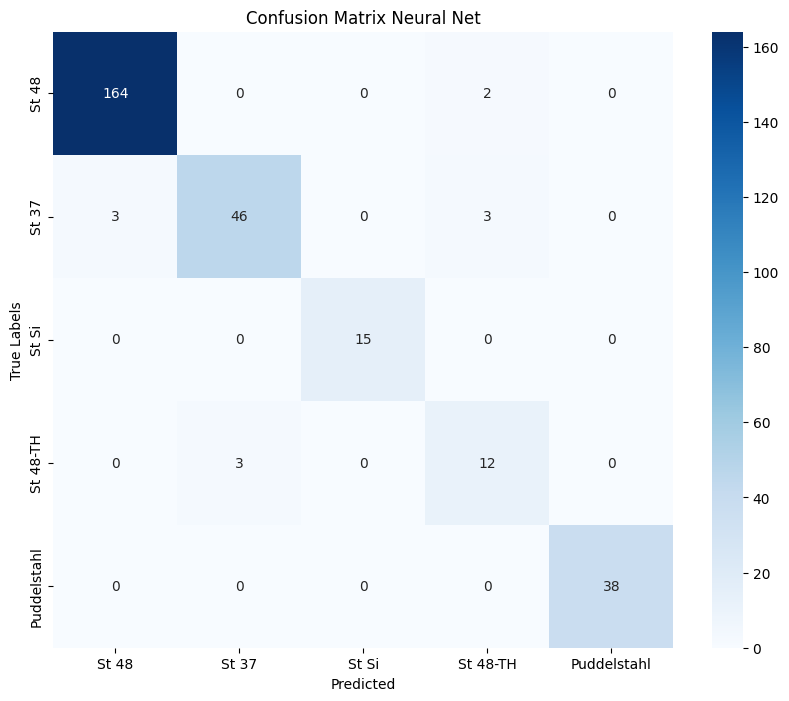

In [14]:
conf_matrix = confusion_matrix(y_test, predicted_classes)

plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', 
            xticklabels=["St 48", "St 37", "St Si", "St 48-TH", "Puddelstahl"], yticklabels=["St 48", "St 37", "St Si", "St 48-TH", "Puddelstahl"])
plt.xlabel('Predicted')
plt.ylabel('True Labels')
plt.title('Confusion Matrix Neural Net')
#plt.savefig('Confusion_Matrix_NN.jpg', format='jpg')
plt.show()

In [28]:
new_labels = ["St 48", "St 37", "St Si", "St 48-TH", "Puddelstahl"]

report = classification_report(y_test, predicted_classes, target_names=new_labels)
print(report)

              precision    recall  f1-score   support

       St 48       0.98      0.99      0.98       166
       St 37       0.94      0.88      0.91        52
       St Si       1.00      1.00      1.00        15
    St 48-TH       0.71      0.80      0.75        15
 Puddelstahl       1.00      1.00      1.00        38

    accuracy                           0.96       286
   macro avg       0.93      0.93      0.93       286
weighted avg       0.96      0.96      0.96       286



In [15]:
'''
skf = StratifiedKFold(n_splits=9, shuffle=True)

accuracy_scores = []
loss_scores = []

for train_index, test_index in skf.split(X, y):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    model = Sequential()
    model.add(Dense(248, activation='relu', input_dim=X_train.shape[1]))
    model.add(Dense(124, activation='relu'))
    model.add(Dropout(0.5))
    model.add(Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.05)))
    model.add(Dense(32, activation='relu'))
    model.add(Dense(len(np.unique(y)), activation='softmax'))
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

    model.fit(X_train, y_train, epochs=800, batch_size=8, verbose=0)

    loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
    
    accuracy_scores.append(accuracy)
    loss_scores.append(loss)

avg_accuracy = np.mean(accuracy_scores)
avg_loss = np.mean(loss_scores)

print("Average accuracy over all folds:", avg_accuracy)
print("Average loss over all folds:", avg_loss)
'''

'\nskf = StratifiedKFold(n_splits=9, shuffle=True)\n\naccuracy_scores = []\nloss_scores = []\n\nfor train_index, test_index in skf.split(X, y):\n    X_train, X_test = X[train_index], X[test_index]\n    y_train, y_test = y[train_index], y[test_index]\n\n    model = Sequential()\n    model.add(Dense(248, activation=\'relu\', input_dim=X_train.shape[1]))\n    model.add(Dense(124, activation=\'relu\'))\n    model.add(Dropout(0.5))\n    model.add(Dense(64, activation=\'relu\', kernel_regularizer=regularizers.l2(0.05)))\n    model.add(Dense(32, activation=\'relu\'))\n    model.add(Dense(len(np.unique(y)), activation=\'softmax\'))\n    model.compile(optimizer=\'adam\', loss=\'sparse_categorical_crossentropy\', metrics=[\'accuracy\'])\n\n    model.fit(X_train, y_train, epochs=800, batch_size=8, verbose=0)\n\n    loss, accuracy = model.evaluate(X_test, y_test, verbose=0)\n    \n    accuracy_scores.append(accuracy)\n    loss_scores.append(loss)\n\navg_accuracy = np.mean(accuracy_scores)\navg_los

## PCA

In [16]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from matplotlib.lines import Line2D
import numpy as np

In [17]:
misclassified_samples = X_test[index_set_wrong_classified]

scaler = StandardScaler()
scaled_wrong_rows = scaler.fit_transform(misclassified_samples)
scaled_wrong_rows

array([[ 6.88510505e-01, -6.32078885e-01,  5.02223868e-01,
         1.85424482e+00,  1.20949599e-01, -6.20504437e-01,
        -1.07596270e+00, -2.76294453e-01, -1.24012671e+00],
       [ 2.08493336e+00, -5.53553834e-01, -6.33238708e-01,
         1.16117528e-01, -2.75745916e-01, -6.20504437e-01,
        -6.46984426e-01, -9.05444429e-01, -8.77945980e-01],
       [ 7.76601573e-02, -6.32078885e-01, -5.35265762e-01,
        -9.39870103e-01,  6.58333640e-01,  1.87472929e-01,
         1.72319094e+00, -9.05444429e-01,  4.14394105e-01],
       [ 3.97359672e-02,  1.71439804e+00,  4.57624243e-01,
        -1.05680833e+00,  5.17645114e-01, -4.16595457e-01,
        -5.37158478e-01,  1.24247210e+00, -1.58773701e-01],
       [-1.18467360e+00, -5.44897529e-01,  5.48285776e-01,
        -2.48871486e-01, -5.91718507e-01,  3.21497610e-01,
         1.23674574e-01, -9.05444429e-01, -7.39778874e-04],
       [ 6.35687526e-01, -6.32078885e-01,  6.33098177e-01,
         1.72608525e+00,  4.96887791e-01, -6.205044

In [18]:
pca = PCA(3)
pca_wrong_rows = pca.fit_transform(scaled_wrong_rows)
pca_wrong_rows

array([[-0.72682712,  2.54632113,  0.55663   ],
       [ 0.00978283,  1.99970036,  0.23252829],
       [ 0.54866403, -1.08152782,  0.25486161],
       [-1.06750095, -0.67730581, -1.98295811],
       [ 0.75292402, -0.31983546,  0.62327428],
       [-0.86629623,  2.41975132,  0.37804235],
       [ 3.42284515, -0.59409847,  0.56278235],
       [-0.9149704 , -1.00045821, -2.78795566],
       [-2.81517101, -2.20299045,  2.95635711],
       [ 2.95380435, -0.5783343 ,  0.19285999],
       [-1.29725467, -0.51122228, -0.98642223]])

In [19]:
training_data = X_train
scaled_training_data = scaler.fit_transform(training_data)
pca_training_data = pca.fit_transform(scaled_training_data)
pca_training_data

array([[ 1.77946384,  0.17009792,  1.02964852],
       [ 6.39431433,  8.7074203 ,  1.42211131],
       [ 1.23501971, -0.96839154,  0.04131957],
       ...,
       [-4.17634187,  2.52631323, -0.70373728],
       [ 1.44564923, -1.42327202, -0.25488519],
       [ 1.16195459, -0.40574104,  0.46694464]])

[1 0 1 1 3 1 3 1 0 3 1]


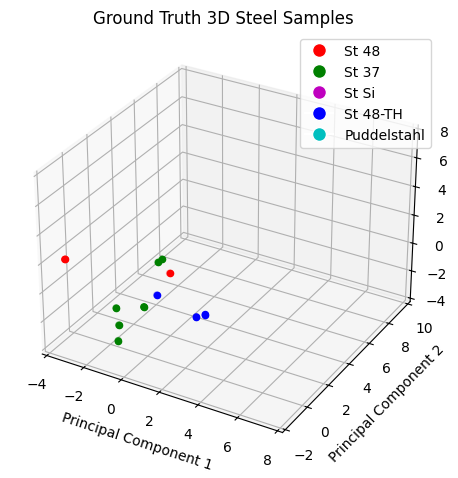

In [20]:
x = pca_wrong_rows[:, 0]
y = pca_wrong_rows[:, 1]
z = pca_wrong_rows[:, 2]

x_tr = pca_training_data[:, 0]
y_tr = pca_training_data[:, 1]
z_tr = pca_training_data[:, 2]

true_categories = y_test[index_set_wrong_classified]
print(true_categories)
train_categories = y_train

rev_classes_dict = {0: "St 48", 1 : "St 37", 2 : "St Si", 3 : "St 48-TH", 4 : "Puddelstahl"}


class_colors = ['r', 'g', 'm', 'b', 'c']
classes = [0, 1, 2, 3, 4]

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

for i in range(len(x)):
        ax.scatter(x[i], y[i], z[i], c=class_colors[true_categories[i]], label=f'Category {true_categories[i]}')
        
#for i in range(len(x_tr)):
#        ax.scatter(x_tr[i], y_tr[i], z_tr[i], c=class_colors[train_categories[i]], label=f'Category {train_categories[i]}', alpha=0.1)


ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
ax.set_zlabel('Principal Component 3')
ax.set_title('Ground Truth 3D Steel Samples')

legend_elements = []
for i in range(len(class_colors)):
    if i in classes:
        indices = np.where(true_categories == i)[0]
        ax.scatter(x[indices], y[indices], z[indices], c=class_colors[i], label= rev_classes_dict[i])
        legend_elements.append(Line2D([0], [0], marker='o', color='w', markerfacecolor=class_colors[i], markersize=10, label= rev_classes_dict[i]))

ax.set_xlim(-4, 8)
ax.set_ylim(-2, 10)
ax.set_zlim(-4, 8)

ax.legend(handles=legend_elements, loc='upper right')

#plt.savefig('GT_PCA_misclass_NN.jpg', format='jpg')

plt.tight_layout()
plt.show()

[3 3 3 0 1 3 1 0 3 1 0]


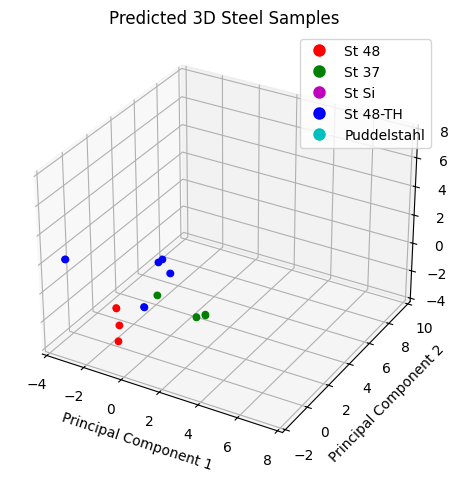

In [21]:
x = pca_wrong_rows[:, 0]
y = pca_wrong_rows[:, 1]
z = pca_wrong_rows[:, 2]

x_tr = pca_training_data[:, 0]
y_tr = pca_training_data[:, 1]
z_tr = pca_training_data[:, 2]

wrong_predicted = predicted_classes[index_set_wrong_classified]
print(wrong_predicted)
train_categories = y_train

rev_classes_dict = {0: "St 48", 1 : "St 37", 2 : "St Si", 3 : "St 48-TH", 4 : "Puddelstahl"}


class_colors = ['r', 'g', 'm', 'b', 'c']
classes = [0, 1, 2, 3, 4]

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

for i in range(len(x)):
        ax.scatter(x[i], y[i], z[i], c=class_colors[wrong_predicted[i]], label=f'Category {wrong_predicted[i]}')
        
#for i in range(len(x_tr)):
#        ax.scatter(x_tr[i], y_tr[i], z_tr[i], c=class_colors[train_categories[i]], label=f'Category {train_categories[i]}', alpha=0.1)


ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
ax.set_zlabel('Principal Component 3')
ax.set_title('Predicted 3D Steel Samples')

legend_elements = []
for i in range(len(class_colors)):
    if i in classes:
        indices = np.where(wrong_predicted == i)[0]
        ax.scatter(x[indices], y[indices], z[indices], c=class_colors[i], label= rev_classes_dict[i])
        legend_elements.append(Line2D([0], [0], marker='o', color='w', markerfacecolor=class_colors[i], markersize=10, label= rev_classes_dict[i]))

ax.set_xlim(-4, 8)
ax.set_ylim(-2, 10)
ax.set_zlim(-4, 8)

ax.legend(handles=legend_elements, loc='upper right')

#plt.savefig('Pred_PCA_allpoints_NN.jpg', format='jpg')

plt.tight_layout()
plt.show()